In [1]:
%matplotlib inline
import time
import numpy as np
import matplotlib.pyplot as plt
import cvxpy as cp

from numpy.linalg import matrix_power
from scipy.linalg import solve_discrete_are
from scipy.linalg import block_diag
from scipy.optimize import linprog
from scipy.spatial import ConvexHull, HalfspaceIntersection

plt.rcParams['figure.figsize'] = (6, 4.5)

Double integrator discrete: $$ x^+ = \begin{bmatrix} 1&1\\0&1\end{bmatrix}x + \begin{bmatrix}0.5\\1\end{bmatrix}u+w$$

- State constraints: $\mathbb X = \{x \mid [0\;1]x \le 2\}$
- Control constraints: $\mathbb U = \{u \mid |u| \le 1\}$
- Noise $W = \{w \mid \|w\|_\infty \le 0.1\}$
- Cost: $\ell(x,u)=\tfrac12(x^\top Qx + u^\top Ru)$, $Q=I$, $R=0.01$; predicted step $N=9$

Every polyhedron is stored in **H-rep** $\{x \mid Hx \le h\}$; for $W$ and $Z$ we also store their **vertices** (V-rep) as this makes computing the Minkowski sum straightforward

In [2]:
A = np.array([[1.,1.],
              [0.,1.]])
B = np.array([[0.5],
              [1.0]])

nx, nu = B.shape

Q = np.eye(2)
R = np.array([[0.01]])
N = 9


H_X = np.array([[0., 1.]]); h_X = np.array([2.])
u_max = 1.0
w_max = 0.1
W_V = 0.1 * np.array([[1, 1], [1, -1], [-1, -1], [-1, 1]])  
H_W = np.vstack([np.eye(2), -np.eye(2)]); h_W = w_max * np.ones(4)



Control law $K$ and terminal cost $V_f(x) = \frac{1}{2} x^TPx$

$u = Kx$ is LQR unconstrainted optimization $(A,B,Q,R)$ and $P$ is solution of Ricacati discrete (DARE):

$P = A^TPA - A^TPB(R + B^TPB)^{-1}B^TPA + Q, \quad K = - (R + B^TPB)^{-1}B^TPA $

In [3]:
P = solve_discrete_are(A, B, Q, R)
K = -np.linalg.inv(R + B.T @ P @ B) @ B.T @ P @ A
AK = A + B @ K

print("P = \n", P.round(4))
print("K = \n", K.round(4))
print("AK = \n", AK.round(4))
print("eigenvalues of AK = \n", np.linalg.eigvals(AK).round(4), " -> stable (|$lambda$| < 1)")



P = 
 [[2.0066 0.5099]
 [0.5099 1.2682]]
K = 
 [[-0.6609 -1.3261]]
AK = 
 [[ 0.6696  0.337 ]
 [-0.6609 -0.3261]]
eigenvalues of AK = 
 [0.3303+0.j 0.0132+0.j]  -> stable (|$lambda$| < 1)


- **Minkowski sum**: $A \oplus B = \{a + b\}$: for a polytope difined by its vertices, take all possible sums of the vertices and them form their convex hull
- **Pontryagin different**: $A \ominus B = \{a \mid a\oplus B\subseteq A\}$: the set consists of all points $a$ such that, when the set $B$ is translated to be positioned at $a$, the entire set $B$ remains contained within $A$
- Assume $A = \{ x | H_x \leq h\}$, including of the rows $H_ix \leq h_i$. We have the following sequence of equivalences:
- $a \in A\ominus B \leftrightarrow a + b \in A \quad \forall b \in B \leftrightarrow H_i(a + b) \leq h_i \quad \forall i, \forall b \in B \leftrightarrow H_i a + \underbrace{\max_{b \in B} H_i b}_{h_B(H_i)} \leq h_i \; \forall i$

In [12]:
def hull_vertices(V):
    """The function perfomrs two taks: 
    removing redundant points (located inside or on the edges) 
    and sorting the vertices in order."""
    return V[ConvexHull(V).vertices]

def vrep_to_hrep(V):
    """Convert a set of vertices V to the corresponding half-space representation 
    (H-representation) of the convex hull."""
    eq = ConvexHull(V).equations       # eq[:, :2]x + eq[:, 2] <= 0
    return eq[:, :-1], -eq[:, -1]

def hrep_to_vrep(H, h):
    """Convert a half-space representation (H-representation) 
    of a convex polytope to its vertex representation (V-representation)."""

    norms = np.linalg.norm(H, axis=1)
    res = linprog(np.r_[np.zeros(H.shape[1]), -1], A_ub=np.c_[H, norms], b_ub=h,
                  bounds=[(None, None)] * H.shape[1] + [(0, None)])
    hs = HalfspaceIntersection(np.c_[H, -h], res.x[:-1])
    return hull_vertices(hs.intersections)

def minkowski_sum(V1, V2):
    """Compute the Minkowski sum of two sets of vertices V1 and V2."""
    return hull_vertices((V1[:, None, :] + V2[None, :, :]).reshape(-1, V1.shape[1]))

def support(V, d):
    """Compute the support function of a set of vertices V in direction d."""
    return np.max(V @ d)

def pontryagin_diff(H, h, V):
    """"{x | Hx <= h} \ominus V"""
    return H, h - np.array([support(V, Hi) for Hi in H])

def plot_poly(V, ax, **kw):
    ax.add_patch(plt.Polygon(V, closed=True,**kw))
    ax.autoscale_view()



<>:32: SyntaxWarning: "\o" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\o"? A raw string is also an option.
<>:32: SyntaxWarning: "\o" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\o"? A raw string is also an option.
C:\Users\tth225\AppData\Local\Temp\ipykernel_29656\3299276411.py:32: SyntaxWarning: "\o" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\o"? A raw string is also an option.
  """"{x | Hx <= h} \ominus V"""


We require a set $Z$ such that $A_K Z \oplus W \subseteq Z$. The smallest such set is $Z_\infty = \bigoplus_{i=0}^{\infty} A_K^i W$ (which is generally not a polytope).
The paper employs an **outer approximation** as proposed by Raković et al. (2004):

1. Determine $s$ and $\alpha \in [0, 1)$ such that $A_K^s W \subseteq \alpha W$. Given $W = \{Hw \le h\}$:
   $$\alpha(s) = \max_j \frac{h_W\big((A_K^s)^\top H_j\big)}{h_j}$$
2. Define $F_s = \bigoplus_{i=0}^{s-1} A_K^i W$ and
   $$Z = (1-\alpha)^{-1} F_s$$
   This set is disturbance-invariant, and it satisfies $Z_\infty \subseteq Z \subseteq (1-\alpha)^{-1}Z_\infty$ — the smaller the value of $\alpha$, the closer $Z$ is to $Z_\infty$.

In [5]:
def alpha_of_s(s):
    M = matrix_power(AK, s)
    return max(support(W_V, M.T @ H_W[j]) / h_W[j] for j in range(len(h_W)))



In [6]:
alpha_target = 1e-3
n_extra = 3            # number of dropped terms printed for comparison

print(f"alpha_target = {alpha_target:.0e}")
print(f"{'i (age)':>7} | {'alpha(i)':>9} | {'<= target?':>10} | {'A_K^i W':>8} | "
      f"{'Cumulative F_(i+1)':>18} | {'#vertices':>9}")
print("-" * 78)

s, F = None, None
i = 0
while s is None or i < s + n_extra:
    a = alpha_of_s(i)                                   # A_K^i W ⊆ alpha(i) W
    if s is None and i >= 1 and a <= alpha_target:      # first term small enough -> cut here
        s, alpha = i, a
        print(f"{f'--- s = {s}: dropped (i >= s) ---':^78}")
    term = W_V @ matrix_power(AK, i).T                  # vertices of A_K^i W
    F = term if F is None else minkowski_sum(F, term)   # F_(i+1) = F_i ⊕ A_K^i W
    print(f"{i:>7} | {a:9.2e} | {str(a <= alpha_target):>10} | {np.abs(term[:, 1]).max():8.5f} | "
          f"{F[:, 1].max():18.5f} | {len(F):>9}")
    if s is None:
        F_s = F.copy()                                  # keep F_s = W ⊕ ... ⊕ A_K^(s-1) W
    i += 1

Z_V = F_s / (1 - alpha)
H_Z, h_Z = vrep_to_hrep(Z_V)

print("-" * 78)
print(f"s = {s}, alpha = {alpha:.2e}, 1/(1-alpha) = {1 / (1 - alpha):.5f}")
print(f"F_s           : max x2 = {F_s[:, 1].max():.5f}")
print(f"Z = F_s/(1-a) : max x2 = {Z_V[:, 1].max():.5f}  (>= F_(s+{n_extra}) = {F[:, 1].max():.5f} ? "
      f"{Z_V[:, 1].max() >= F[:, 1].max()})")
print(f"Z has {len(Z_V)} vertices")

alpha_target = 1e-03
i (age) |  alpha(i) | <= target? |  A_K^i W | Cumulative F_(i+1) | #vertices
------------------------------------------------------------------------------
      0 |  1.00e+00 |      False |  0.10000 |            0.10000 |         4
      1 |  1.01e+00 |      False |  0.09869 |            0.19869 |         8
      2 |  3.43e-01 |      False |  0.03434 |            0.23303 |        12
      3 |  1.14e-01 |      False |  0.01136 |            0.24439 |        16
      4 |  3.75e-02 |      False |  0.00375 |            0.24815 |        20
      5 |  1.24e-02 |      False |  0.00124 |            0.24939 |        24
      6 |  4.10e-03 |      False |  0.00041 |            0.24980 |        28
      7 |  1.35e-03 |      False |  0.00014 |            0.24993 |        32
                       --- s = 8: dropped (i >= s) ---                        
      8 |  4.47e-04 |       True |  0.00004 |            0.24998 |        34
      9 |  1.48e-04 |       True |  0.00001 |      

A_K Z ⊕ W ⊆ Z ? True


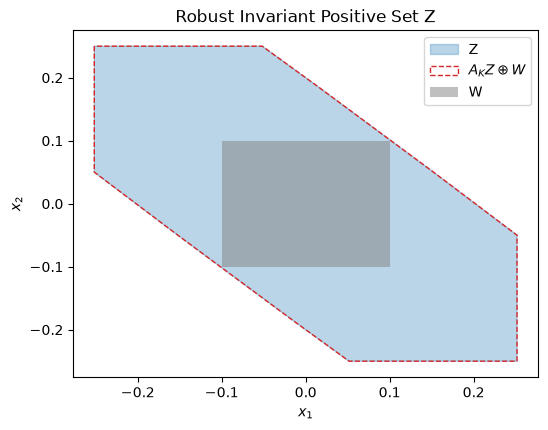

In [7]:
AKZ_W = minkowski_sum(Z_V @ AK.T, W_V)
print("A_K Z ⊕ W ⊆ Z ?", np.all(H_Z @ AKZ_W.T <= h_Z[:, None] + 1e-9))

fig, ax = plt.subplots()
plot_poly(Z_V, ax, fc='tab:blue', alpha=0.3, ec='tab:blue', label='Z')
plot_poly(AKZ_W, ax, fill=False, ec='tab:red', ls='--', label=r'$A_K Z \oplus W$')
plot_poly(W_V, ax, fc='gray', alpha=0.5, label='W')
ax.set_xlabel('$x_1$'); ax.set_ylabel('$x_2$'); ax.legend(); ax.set_title('Robust Invariant Positive Set Z')
plt.show()

In [13]:
H_Xbar, h_Xbar = pontryagin_diff(H_X, h_X, Z_V)
KZ_max = np.max(np.abs(Z_V @ K[0]))                 # max |Kz|, z ∈ Z
u_bar = u_max - KZ_max

print(f"X̄ : x2 <= {h_Xbar[0]:.4f}   (original: x2 <= 2)")
print(f"Ū : |u| <= {u_bar:.4f}  (original: |u| <= 1)")

X̄ : x2 <= 1.7500   (original: x2 <= 2)
Ū : |u| <= 0.7025  (original: |u| <= 1)


In [16]:
H0 = np.vstack([H_Xbar, K, -K])
h0 = np.concatenate([h_Xbar, [u_bar, u_bar]])
row_names = [f"H_Xbar[{j}] x" for j in range(len(h_Xbar))] + ["K x", "-K x"]

def lp_max(c, H, h):
    """max c^T x  s.t.  Hx <= h   (np.inf if unbounded)"""
    res = linprog(-c, A_ub=H, b_ub=h, bounds=[(None, None)] * nx)
    return -res.fun if res.status == 0 else np.inf

W = 86
print(f"Initial set (k = 0): {len(h0)} rows  ->  " + ", ".join(f"{n} <= {v:.4f}" for n, v in zip(row_names, h0)))

Hf, hf = H0.copy(), h0.copy()
row_k = [0] * len(h0)                     # which k each row of Hf comes from
k = 1
while True:
    Hk = H0 @ matrix_power(AK, k)         # constraints after k steps of u = Kx
    print(f"\nk = {k}: constraints after {k} step(s) of u = Kx   (current set: {len(hf)} rows)")
    print(f"{'row':>3} | {'constraint':>13} | {'row of H0 A_K^k':>20} | {'max over set':>12} | "
          f"{'h0':>7} | redundant?")
    print("-" * W)
    flags = []
    for i in range(len(h0)):
        m = lp_max(Hk[i], Hf, hf)
        red = m <= h0[i] + 1e-9
        flags.append(red)
        m_str = "unbounded" if np.isinf(m) else f"{m:.4f}"
        print(f"{i:>3} | {row_names[i]:>13} | [{Hk[i, 0]:8.4f}, {Hk[i, 1]:8.4f}] | {m_str:>12} | "
              f"{h0[i]:7.4f} | {red}")
    print("-" * W)
    if all(flags):
        print("-> all rows redundant: STOP")
        break
    print(f"-> not all redundant: add H0 A_K^{k} ({len(h0)} rows) to the set")
    Hf, hf = np.vstack([Hf, Hk]), np.concatenate([hf, h0])
    row_k += [k] * len(h0)
    k += 1

Xf_V = hrep_to_vrep(Hf, hf)

print(f"\nk* = {k - 1}  ->  X_f = {{x | H0 A_K^k x <= h0, k = 0..{k - 1}}}")
print(f"{'row':>3} | {'from k':>6} | {'constraint':>13} | {'Hf row':>20} | {'hf':>7}")
print("-" * 62)
for r in range(len(hf)):
    print(f"{r:>3} | {row_k[r]:>6} | {row_names[r % len(h0)]:>13} | "
          f"[{Hf[r, 0]:8.4f}, {Hf[r, 1]:8.4f}] | {hf[r]:7.4f}")
print("-" * 62)
print(f"X_f has {len(hf)} rows and {len(Xf_V)} vertices:")
for v in Xf_V:
    print(f"   ({v[0]:8.4f}, {v[1]:8.4f})")

# Check A1 at the vertices (enough because X_f is convex)
print("\nA1: A_K X_f ⊆ X_f ?       ", np.all(Hf @ (Xf_V @ AK.T).T <= hf[:, None] + 1e-9))
print("A1: |K x| <= u_bar on X_f ?", np.all(np.abs(Xf_V @ K[0]) <= u_bar + 1e-9))
# Check A2
print("A2: ||A_K'PA_K + Q + K'RK - P|| =", np.linalg.norm(AK.T @ P @ AK + Q + K.T @ R @ K - P))


Initial set (k = 0): 3 rows  ->  H_Xbar[0] x <= 1.7500, K x <= 0.7025, -K x <= 0.7025

k = 1: constraints after 1 step(s) of u = Kx   (current set: 3 rows)
row |    constraint |      row of H0 A_K^k | max over set |      h0 | redundant?
--------------------------------------------------------------------------------------
  0 |   H_Xbar[0] x | [ -0.6609,  -0.3261] |       2.4525 |  1.7500 | False
  1 |           K x | [  0.4338,   0.2097] |    unbounded |  0.7025 | False
  2 |          -K x | [ -0.4338,  -0.2097] |       1.6177 |  0.7025 | False
--------------------------------------------------------------------------------------
-> not all redundant: add H0 A_K^1 (3 rows) to the set

k = 2: constraints after 2 step(s) of u = Kx   (current set: 6 rows)
row |    constraint |      row of H0 A_K^k | max over set |      h0 | redundant?
--------------------------------------------------------------------------------------
  0 |   H_Xbar[0] x | [ -0.2270,  -0.1164] |       0.3652 |  1.7500 

In [17]:
x_par = cp.Parameter(nx)          # measured state of the system
x0 = cp.Variable(nx)              # initial state of the nominal model
U = cp.Variable(N)                # nominal control sequence

tube_con = [H_Z @ (x_par - x0) <= h_Z]          # x ∈ x0 ⊕ Z
nom_con = []                                     # (9)–(11): only depend on (x0, U)
cost = 0
xi = x0
Xbar_pred = [xi]
for i in range(N):
    nom_con += [H_Xbar @ xi <= h_Xbar, cp.abs(U[i]) <= u_bar]
    cost += 0.5 * (cp.quad_form(xi, Q) + R[0, 0] * cp.square(U[i]))
    xi = A @ xi + B[:, 0] * U[i]
    Xbar_pred.append(xi)
nom_con += [Hf @ xi <= hf]
cost += 0.5 * cp.quad_form(xi, P)

prob = cp.Problem(cp.Minimize(cost), tube_con + nom_con)
print("Is it a convex QP (DCP)?", prob.is_dcp())

def tube_mpc(x):
    """Solve P*_N(x); return κ*_N(x), x0*, u*, V*_N(x)."""
    x_par.value = x
    prob.solve(solver=cp.CLARABEL)
    if prob.status != cp.OPTIMAL:
        raise RuntimeError(f"P*_N(x) is infeasible at x = {x}: {prob.status}")
    u = U.value[0] + K[0] @ (x - x0.value)
    return u, x0.value.copy(), U.value.copy(), prob.value

Is it a convex QP (DCP)? True


In [18]:
for x_test in [np.zeros(2), Z_V[0], 0.5 * Z_V[3], Z_V[10]]:
    u, x0s, Us, V = tube_mpc(x_test)
    print(f"x={x_test.round(3)}  V*={V:.1e}  x0*={x0s.round(6)}  "
          f"κ*={u:.5f}  Kx={K[0] @ x_test:.5f}")

x=[0. 0.]  V*=1.3e-19  x0*=[-0.  0.]  κ*=0.00000  Kx=0.00000
x=[ 0.052 -0.25 ]  V*=1.2e-09  x0*=[-1.0e-05 -3.8e-05]  κ*=0.29747  Kx=0.29747
x=[ 0.126 -0.025]  V*=2.3e-18  x0*=[0. 0.]  κ*=-0.05010  Kx=-0.05010
x=[ 0.241 -0.039]  V*=6.9e-10  x0*=[1.3e-05 2.4e-05]  κ*=-0.10751  Kx=-0.10751


In [33]:
rng = np.random.default_rng(0)
T_sim = 30
x = np.array([-5., -2.])
X_traj, X0_traj, U_traj, V_traj, L_traj = [x.copy()], [], [], [], []
t0 = time.perf_counter()
for t in range(T_sim):
    u, x0s, Us, V = tube_mpc(x)
    X0_traj.append(x0s); U_traj.append(u); V_traj.append(V)
    L_traj.append(0.5 * (x0s @ Q @ x0s + R[0, 0] * Us[0] ** 2))   # ℓ(x0*, κ0_N(x0*))
    w = W_V[rng.integers(4)]
    x = A @ x + B[:, 0] * u + w
    X_traj.append(x.copy())
print(f"Average solving time: {(time.perf_counter() - t0) / T_sim * 1e3:.1f} ms/step")
X_traj, X0_traj, U_traj = map(np.array, (X_traj, X0_traj, U_traj))

tol = 1e-6   # solver tolerance
print(f"max x2 = {X_traj[:, 1].max():.4f}  (<= 2 ? {X_traj[:, 1].max() <= 2 + tol})")
print(f"max |u| = {np.abs(U_traj).max():.8f}  (<= 1 ? {np.abs(U_traj).max() <= 1 + tol})")

Average solving time: 1.7 ms/step
max x2 = 1.8000  (<= 2 ? True)
max |u| = 1.00000000  (<= 1 ? True)


C:\Users\tth225\AppData\Local\Temp\ipykernel_29656\13329901.py:7: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "k-." (-> color='k'). The keyword argument will take precedence.
  ax.plot(X_traj[:, 0], X_traj[:, 1], 'k-.', lw=1,color='r', label='$x(i)$ (actual)')


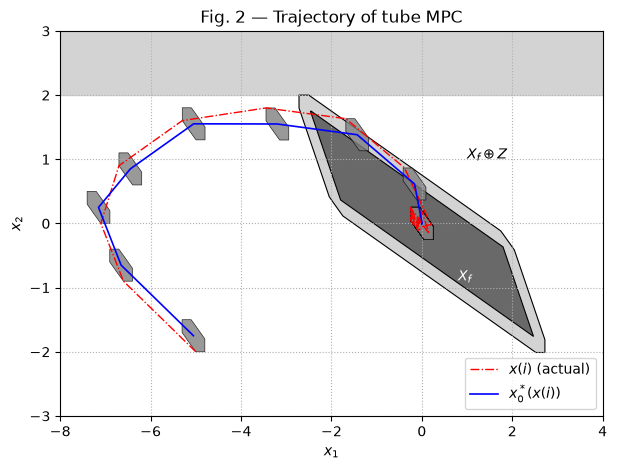

In [34]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.axhspan(2, 3, color='lightgray')                            # region where x2 > 2 is violated
plot_poly(minkowski_sum(Xf_V, Z_V), ax, fc='lightgray', ec='k', lw=0.8)
plot_poly(Xf_V, ax, fc='dimgray', ec='k', lw=0.8)
for x0s in X0_traj:
    plot_poly(x0s + Z_V, ax, fc='gray', ec='k', lw=0.5, alpha=0.8)
ax.plot(X_traj[:, 0], X_traj[:, 1], 'k-.', lw=1,color='r', label='$x(i)$ (actual)')
ax.plot(X0_traj[:, 0], X0_traj[:, 1], 'b-', lw=1.2, label='$x_0^*(x(i))$')
ax.text(0.8, -0.9, '$X_f$', color='w'); ax.text(1.0, 1.0, r'$X_f\oplus Z$')
ax.set_xlim(-8, 4); ax.set_ylim(-3, 3)
ax.set_xlabel('$x_1$'); ax.set_ylabel('$x_2$'); ax.legend(loc='lower right'); ax.grid(ls=':')
ax.set_title('Fig. 2 — Trajectory of tube MPC')
plt.show()

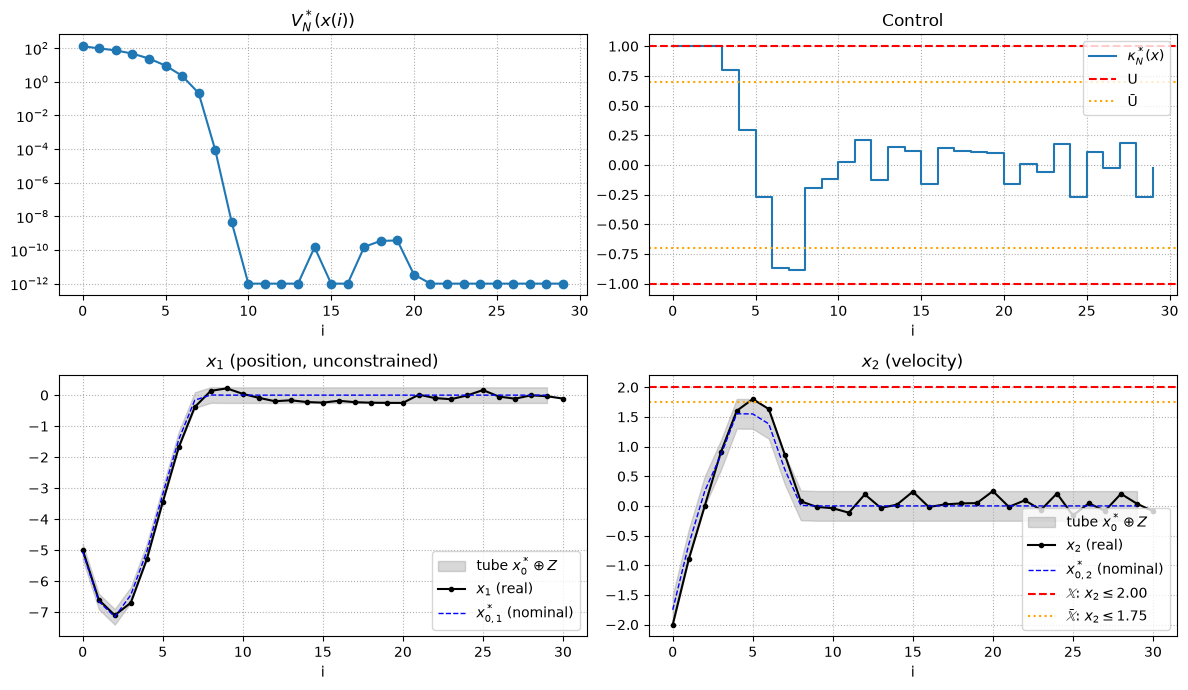

In [38]:
V_traj = np.array(V_traj); L_traj = np.array(L_traj)
t_x = np.arange(len(X_traj))          # x(0) ... x(T_sim)
t_u = np.arange(T_sim)                # steps where the QP was solved
z_min, z_max = Z_V.min(axis=0), Z_V.max(axis=0)   # extent of Z in x1 and x2

fig, axs = plt.subplots(2, 2, figsize=(12, 7))

# (0,0) Lyapunov function
ax = axs[0, 0]
ax.semilogy(t_u, np.maximum(V_traj, 1e-12), 'o-')
ax.set_title('$V_N^*(x(i))$'); ax.set_xlabel('i'); ax.grid(ls=':')

# (0,1) Control
ax = axs[0, 1]
ax.step(t_u, U_traj, where='post', label=r'$\kappa_N^*(x)$')
ax.axhline(u_max, c='r', ls='--'); ax.axhline(-u_max, c='r', ls='--', label='U')
ax.axhline(u_bar, c='orange', ls=':'); ax.axhline(-u_bar, c='orange', ls=':', label='Ū')
ax.set_title('Control'); ax.set_xlabel('i'); ax.legend(); ax.grid(ls=':')

# (1,0) x1: no constraint on x1
ax = axs[1, 0]
ax.fill_between(t_u, X0_traj[:, 0] + z_min[0], X0_traj[:, 0] + z_max[0],
                color='gray', alpha=0.3, label=r'tube $x_0^*\oplus Z$')
ax.plot(t_x, X_traj[:, 0], 'k.-', label='$x_1$ (real)')
ax.plot(t_u, X0_traj[:, 0], 'b--', lw=1, label='$x_{0,1}^*$ (nominal)')
ax.set_title('$x_1$ (position, unconstrained)'); ax.set_xlabel('i'); ax.legend(); ax.grid(ls=':')

# (1,1) x2 with X and X_bar
ax = axs[1, 1]
ax.fill_between(t_u, X0_traj[:, 1] + z_min[1], X0_traj[:, 1] + z_max[1],
                color='gray', alpha=0.3, label=r'tube $x_0^*\oplus Z$')
ax.plot(t_x, X_traj[:, 1], 'k.-', label='$x_2$ (real)')
ax.plot(t_u, X0_traj[:, 1], 'b--', lw=1, label='$x_{0,2}^*$ (nominal)')
ax.axhline(h_X[0], c='r', ls='--', label=rf'$\mathbb{{X}}$: $x_2 \leq {h_X[0]:.2f}$')
ax.axhline(h_Xbar[0], c='orange', ls=':', label=rf'$\bar{{\mathbb{{X}}}}$: $x_2 \leq {h_Xbar[0]:.2f}$')
ax.set_title('$x_2$ (velocity)'); ax.set_xlabel('i'); ax.legend(loc='lower right'); ax.grid(ls=':')

plt.tight_layout(); plt.show()


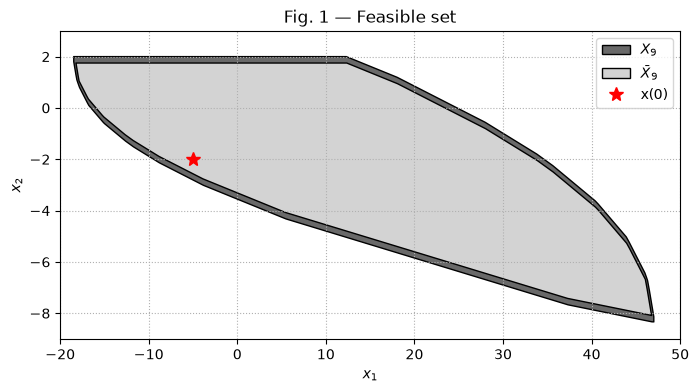

In [37]:
d_par = cp.Parameter(nx)
prob_supp = cp.Problem(cp.Maximize(d_par @ x0), nom_con)

angles = np.linspace(0, 2 * np.pi, 180, endpoint=False)
D = np.c_[np.cos(angles), np.sin(angles)]
h_XbarN = []
for d in D:
    d_par.value = d
    prob_supp.solve(solver=cp.CLARABEL)
    h_XbarN.append(prob_supp.value)
h_XbarN = np.array(h_XbarN)
h_XN = h_XbarN + np.array([support(Z_V, d) for d in D])

XbarN_V = hrep_to_vrep(D, h_XbarN)
XN_V = hrep_to_vrep(D, h_XN)

fig, ax = plt.subplots(figsize=(8, 4))
plot_poly(XN_V, ax, fc='dimgray', ec='k', label=f'$X_{N}$')
plot_poly(XbarN_V, ax, fc='lightgray', ec='k', label=rf'$\bar X_{N}$')
ax.plot(*X_traj[0], 'r*', ms=10, label='x(0)')
ax.set_xlim(-20, 50); ax.set_ylim(-9, 3); ax.grid(ls=':')
ax.set_xlabel('$x_1$'); ax.set_ylabel('$x_2$'); ax.legend(); ax.set_title('Fig. 1 — Feasible set')
plt.show()